# 14 — The textured 3-D globe

Notebooks 08–12 project the Earth onto a **2-D** axes: an orthographic `Map` is a disc, and `Map.rotate` spins it
by sweeping the projection's centre longitude. This notebook is the other kind of globe — an actual **sphere in
3-D**, drawn on a matplotlib `Axes3D`, with a texture wrapped around it and a tilted polar axis it spins about.

It is the usual three-package split:

- **pyramids** reprojects the raster to lon/lat and reads the band (the GIS).
- **cleopatra**'s `TexturedGlobeGlyph` owns the sphere: the mesh, the axial tilt, the lighting, the render.
- **Digital-Earth**'s `TexturedGlobe` joins them — it turns geodata into the texture the glyph wants, and maps
  lon/lat back onto the drawn surface so overlays land in the right place.

> **Which globe do I want?** Use `Map(globe=True)` for a cartographic figure — coastlines, a graticule, a
> colorbar, limb-clipping, everything in notebooks 08–12. Use `TexturedGlobe` when you want the planet *as an
> object*: a spinning, lit sphere for a title slide, a poster, or an animation. It is a presentation renderer,
> not a projection.

## Setup

Everything here is offline: one synthetic global field built with numpy + pyramids, and the small committed
catchment raster. (Paths are relative to **this notebook**, which is where the kernel runs.)

In [1]:
%matplotlib inline
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from cleopatra.glyphs.base.animation import embed_gif
from pyramids.dataset import Dataset, GeoReference

from digitalearth.static import TexturedGlobe

DATA = Path('../../examples/data')

# A synthetic 1-degree global field: a temperature-like pattern, warm at the equator, with some
# longitudinal structure so the rotation is visible.
lat = np.linspace(90, -90, 180)
lon = np.linspace(-180, 180, 360)
LON, LAT = np.meshgrid(lon, lat)
field = (30 * np.cos(np.deg2rad(LAT)) - 12
         + 6 * np.sin(np.deg2rad(3 * LON)) * np.cos(np.deg2rad(LAT))).astype('float32')

GLOBAL = Dataset.from_array(arr=field, geo_ref=GeoReference(geo=(-180.0, 1.0, 0.0, 90.0, 0.0, -1.0), epsg=4326))
print(GLOBAL.shape, GLOBAL.epsg, float(field.min()).__round__(1), float(field.max()).__round__(1))

(1, 180, 360) 4326 -12.0 24.0


## 1. A raster on a sphere — `TexturedGlobe.from_dataset`

`from_dataset` does four things: reprojects to EPSG:4326 (pyramids), reads the band with nodata masked to
`NaN`, colour-maps it through cleopatra's colormap resolver, and pastes the result into a **global** canvas.

The texture is *equirectangular*: row 0 is +90°, the last row −90°, column 0 is −180° and the last column
+180°. That is the layout the glyph samples its sphere from, so any array in that convention can be used
directly.

`n_lon` / `n_lat` set the **sphere mesh**, which is what the render time scales with — matplotlib draws one
polygon per face on the CPU. The default (180×90) is a good still; drop it for animations.

texture: (1440, 2880, 4) | axial tilt: 23.44


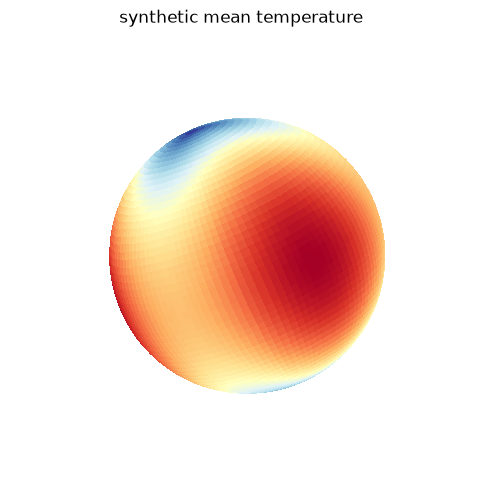

In [2]:
globe = TexturedGlobe.from_dataset(GLOBAL, cmap='RdYlBu_r', n_lon=120, n_lat=60)
fig, ax = globe.draw(spin=0.0)
ax.set_title('synthetic mean temperature')
print('texture:', globe.glyph.texture.shape, '| axial tilt:', globe.glyph.tilt_deg)

## 2. Spinning it — `spin`

`spin` rotates the sphere **about its own tilted polar axis**, which is what a planet actually does: the tilt
stays fixed in space while the surface turns underneath it. The texture is sampled once and cached, so each
extra frame is only a small matrix multiply — this is what makes the animation cheap.

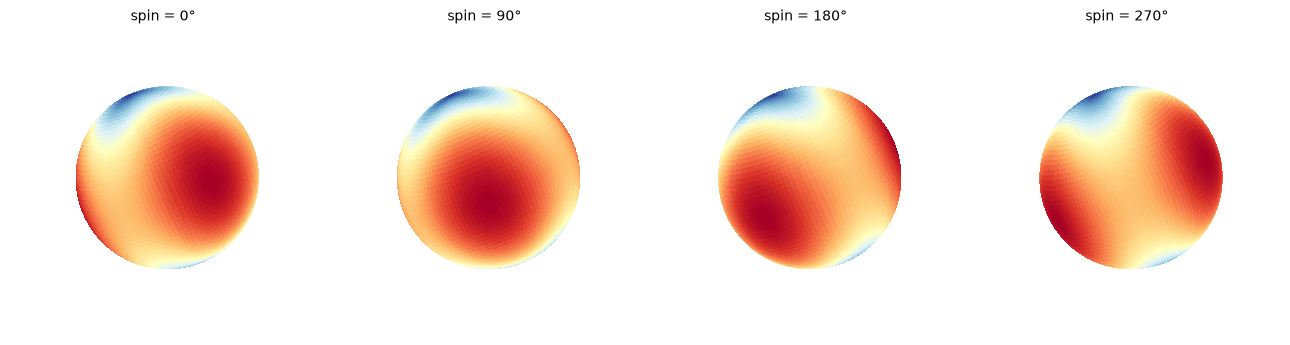

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), subplot_kw={'projection': '3d'})
for spin, sub in zip([0, 90, 180, 270], axes):
    globe.draw(ax=sub, spin=float(spin))
    sub.set_title(f'spin = {spin}°', fontsize=10)
fig.tight_layout()

## 3. Lighting — a day/night terminator

Pass a `sun` direction (a world-space vector, `+z` north and `+x` toward the viewer at `spin=0`) and the glyph
shades a lambertian terminator across the surface. `ambient` is the floor brightness kept on the night side so
it stays legible instead of going black.

Because the lighting is applied to the already-rotated vertices, a **fixed** sun sweeps the terminator as the
globe spins — exactly the behaviour you want for a day/night animation.

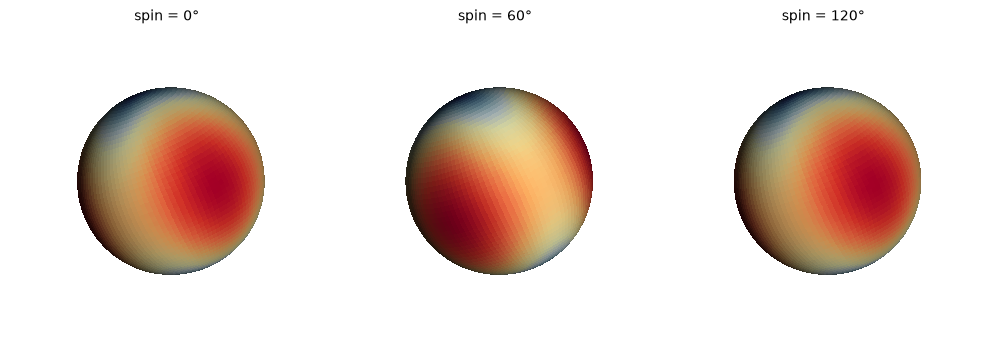

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8), subplot_kw={'projection': '3d'})
for spin, sub in zip([0, 60, 120], axes):
    globe.draw(ax=sub, spin=float(spin), sun=(1.0, 0.35, 0.25), ambient=0.15)
    sub.set_title(f'spin = {spin}°', fontsize=10)
fig.tight_layout()

## 4. A regional raster lands where it belongs

This is the part cleopatra cannot do on its own: it takes a bare array and has no idea *where on Earth* it
goes. `from_dataset` reads the raster's own geotransform, so a regional dataset is pasted onto the globe at its
true lon/lat and everything it does not cover stays **transparent** — it is not stretched over the sphere.

`examples/data/acc4000.tif` is a small catchment in Colombia, in UTM 18N. pyramids reprojects it; the drape
lands near 75° W, 4° N.

In [5]:
catchment = Dataset.read_file(str(DATA / 'acc4000.tif'))
print('source CRS:', catchment.epsg, '| cells:', catchment.shape)

drape = TexturedGlobe.from_dataset(catchment, cmap='viridis', n_lon=120, n_lat=60)
alpha = drape.glyph.texture[..., 3]
rows, cols = np.nonzero(alpha > 0)
rows_lat = 90 - 180 * rows / (alpha.shape[0] - 1)
cols_lon = -180 + 360 * cols / (alpha.shape[1] - 1)
print(f'draped over lon {cols_lon.min():.2f}..{cols_lon.max():.2f}, '
      f'lat {rows_lat.min():.2f}..{rows_lat.max():.2f}')
print(f'opaque cells: {rows.size} of {alpha.size} — the rest of the globe is transparent')

source CRS: 32618 | cells: (1, 13, 14)


draped over lon -75.59..-75.21, lat 4.32..4.57
opaque cells: 8 of 4147200 — the rest of the globe is transparent


C:\Users\main\AppData\Local\Temp\ipykernel_35124\2223750689.py:4: RuntimeWarning: the draped data is finer than the 120x60 sphere mesh, so it falls between the mesh samples and the globe will render without it. Raise the mesh (n_lon=/n_lat=) until a mesh face fits inside the data's footprint.
  drape = TexturedGlobe.from_dataset(catchment, cmap='viridis', n_lon=120, n_lat=60)


Only a handful of cells are opaque, because the catchment is about half a degree across on a 0.125° canvas.
That is the honest picture: a textured globe is a *planetary* renderer, and a small catchment is a few pixels
on it.

A fine texture is not enough on its own, though. The glyph point-samples the texture down to its **mesh**
(`n_lon` × `n_lat`), so anything narrower than one mesh face falls between the samples and never paints — no
matter how many texture cells it covers. At the default 180×90 mesh a face is about 2° wide, sixteen times
coarser than the default texture, so this catchment would render as an empty globe. `from_dataset` warns when
that is about to happen:

```
RuntimeWarning: the draped data is finer than the 180x90 sphere mesh, so it falls between the mesh samples
and the globe will render without it. Raise the mesh (n_lon=/n_lat=) until a mesh face fits inside the data's
footprint.
```

So to actually *see* a small feature: put it on a global backdrop, raise the mesh until a face fits inside it,
and point the camera at it. The mesh below is deliberately fine, which is why this figure takes a few seconds
to draw — that cost is the whole reason the default is coarse.

catchment faces painted on the mesh: 3


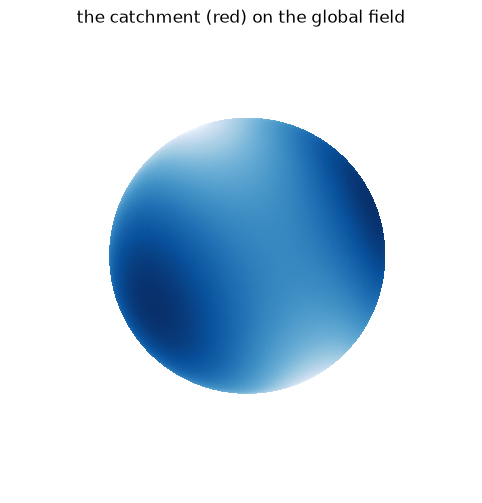

In [6]:
# Composite the catchment onto the global field's texture, then look at South America.
# The mesh must be fine enough to resolve a ~0.5-degree catchment, or it paints nothing at all.
MESH_LON, MESH_LAT = 1440, 720

base = TexturedGlobe.from_dataset(GLOBAL, cmap='Blues', n_lon=MESH_LON, n_lat=MESH_LAT)
mask = drape.glyph.texture[..., 3] > 0
composite = base.glyph.texture.copy()
composite[mask] = [1.0, 0.25, 0.1, 1.0]           # paint the catchment bright red
both = TexturedGlobe(composite, n_lon=MESH_LON, n_lat=MESH_LAT)

fig, ax = both.draw(spin=-75.0, elev=5.0, azim=0.0)
ax.set_title('the catchment (red) on the global field')

# Prove it is actually on the sphere rather than lost between mesh samples.
painted = np.asarray(both.glyph._facecolors)
is_red = np.all(np.isclose(painted[..., :3], [1.0, 0.25, 0.1], atol=0.02), axis=-1)
print(f'catchment faces painted on the mesh: {int(is_red.sum())}')

## 5. Vector overlays — `project` and `points`

To draw anything *on* the sphere you need the same transform the glyph used for its mesh — spin **and** axial
tilt. `TexturedGlobe.project` pushes lon/lat through the glyph's own `transform`, so overlays sit exactly on
the drawn surface rather than drifting from it as you spin.

`points` builds on that: it accepts lon/lat arrays or a pyramids `FeatureCollection`, lifts the points slightly
off the surface so matplotlib does not z-fight them, and — by default — drops the ones on the far side, which
matplotlib would otherwise happily draw straight through the planet.

Text(0.5, 0.92, '7 of 8 cities are on the near side')

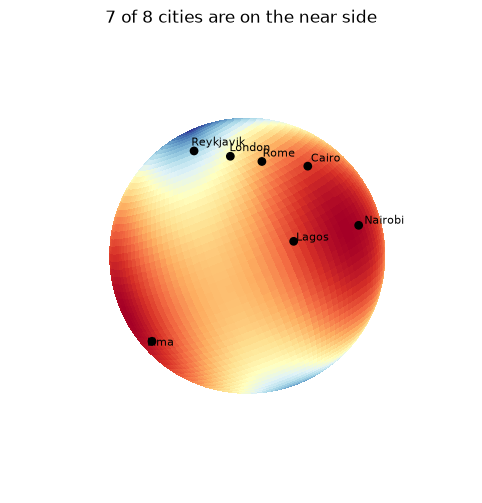

In [7]:
CITIES = {
    'Cairo': (31.2, 30.0), 'London': (-0.1, 51.5), 'Nairobi': (36.8, -1.3),
    'Reykjavik': (-21.9, 64.1), 'Lagos': (3.4, 6.5), 'Rome': (12.5, 41.9),
    'Sydney': (151.2, -33.9), 'Lima': (-77.0, -12.0),
}
city_lon = [v[0] for v in CITIES.values()]
city_lat = [v[1] for v in CITIES.values()]

SPIN = 20.0
fig, ax = globe.draw(spin=SPIN, elev=10.0, azim=0.0)
globe.points(city_lon, lat=city_lat, spin=SPIN, color='black', s=28, depthshade=False)

# Label only the ones actually facing us.
world = globe.project(city_lon, city_lat, spin=SPIN, altitude=0.06)
near = globe.visible(world)
for (name, _), xyz, shown in zip(CITIES.items(), world, near):
    if shown:
        ax.text(*xyz, name, fontsize=8)
ax.set_title(f'{int(near.sum())} of {len(CITIES)} cities are on the near side')

Spin the globe and a different set of cities faces the camera — the overlay follows the surface because it uses
the glyph's transform rather than a re-derived one.

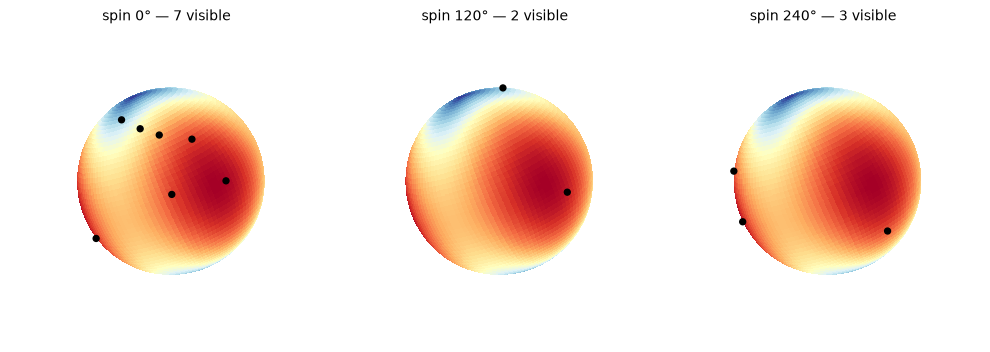

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8), subplot_kw={'projection': '3d'})
for spin, sub in zip([0.0, 120.0, 240.0], axes):
    globe.draw(ax=sub, spin=spin)
    globe.points(city_lon, lat=city_lat, spin=spin, color='black', s=18, depthshade=False)
    visible = globe.visible(globe.project(city_lon, city_lat, spin=spin))
    sub.set_title(f'spin {int(spin)}° — {int(visible.sum())} visible', fontsize=10)
fig.tight_layout()

## 6. Animating a rotation

`animate` returns a matplotlib `FuncAnimation` over a full turn. Keep the mesh small here — every frame is a
full 3-D surface redraw, so resolution costs far more in an animation than in a still.

A fixed `sun` with a spinning globe gives the day/night sweep for free.

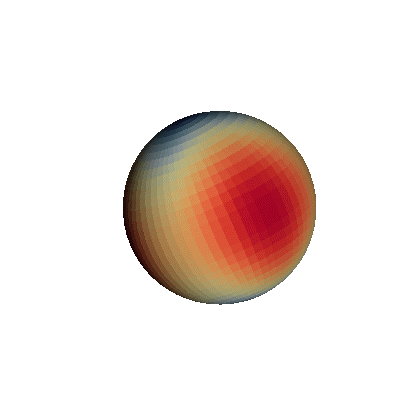

In [9]:
FPS = 8
spinner = TexturedGlobe.from_dataset(GLOBAL, cmap='RdYlBu_r', n_lon=64, n_lat=32,
                                     sun=(1.0, 0.3, 0.2), ambient=0.15)
anim = spinner.spin(n_frames=16, interval=1000 // FPS, figsize=(4.2, 4.2))
gif = embed_gif(anim, FPS)
plt.close(spinner.fig)   # avoid a duplicate static frame under %matplotlib inline
gif

## 7. Saving — render once, encode twice

Drawing frames costs far more than encoding them, so `save_animation` writes the clip and can **derive** a GIF
from that file instead of redrawing every frame:

```python
video, gif = spinner.save_animation('globe.mp4', gif='globe.gif')
```

The frames are rendered once **for that pair of outputs**. Note that the inline preview above was its own
render: `embed_gif` draws the frames to show them here, and the save below draws them again. What
`save_animation` avoids is the *third* render a separate GIF pass would cost. It also raises the intermediate
video to full chroma (`yuv444p`) when a GIF is being derived — the playback-friendly `yuv420p` default halves the
colour resolution *before* the GIF palette
ever sees the frames, and that loss cannot be undone afterwards.

The same method is on `Map`, so a 2-D animation from notebook 12 saves identically.

In [10]:
out = Path(tempfile.mkdtemp())
written = spinner.save_animation(str(out / 'globe.gif'), fps=FPS)
print('wrote', Path(written).name, '-', Path(written).stat().st_size // 1024, 'KB')

wrote globe.gif - 284 KB


## 8. A brand mark — `stamp`

`stamp` places a logo or watermark in a corner of the **figure**, sized as a fraction of it, so it keeps its
proportion at whatever dpi you export at. It lives on `Scene`, so `Map` and the chart scenes have it too; the
globe exposes the same method.

Stamp **last** — the mark is baked from the figure's current size. And note `Scene.save` defaults to
`bbox_inches='tight'`, which crops whitespace and therefore shifts the mark; pass `bbox_inches=None` to keep
the placement exact.

Text(0.5, 0.92, 'with a corner brand mark')

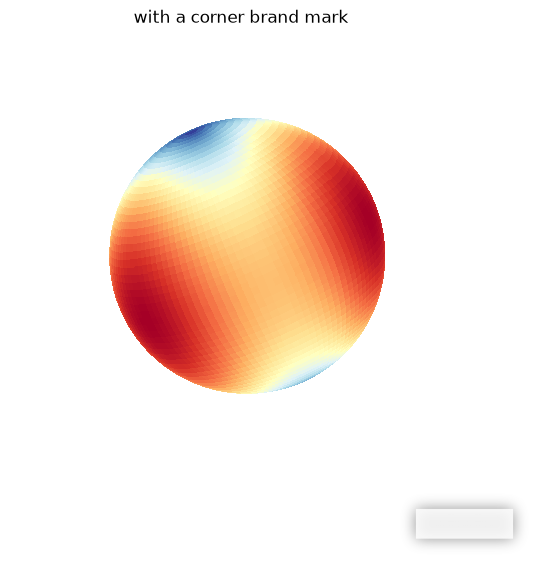

In [11]:
mark = np.zeros((60, 160, 4), dtype=np.uint8)
mark[8:52, 8:152, :3] = 255      # a plain white slab standing in for a logo
mark[8:52, 8:152, 3] = 220

fig, ax = globe.draw(spin=40.0)
globe.stamp(mark, frac=0.18, corner='lower right', shadow=True)
ax.set_title('with a corner brand mark')

## 9. A tile basemap as the texture — `from_provider`

Everything so far textured the globe from a raster. `from_provider` instead fetches a whole-world XYZ basemap
through cleopatra's `world_texture` and uses that, which gives a photographic Earth.

Three things to know:

- It fetches the entire `zoom`-level tile grid — `4**zoom` tiles, so 64 at `zoom=3` and 1024 at `zoom=5`. The
  result is cached on disk per `(provider, zoom, n_lon, n_lat)`, so the cost is paid once per machine.
- Point it at a **bulk-permitting** provider. `Esri.WorldImagery` is the default; OpenStreetMap's usage policy
  forbids bulk downloading, so do not aim it there.
- `n_lon` / `n_lat` name the **texture** grid here (that is `world_texture`'s meaning, and it is the one that
  wants to be large); set the sphere mesh separately with `n_lon` / `n_lat`.

Lit from the side, this is the "planet as an object" the class exists for.

texture: (720, 1440, 4) | mesh: 140 x 70


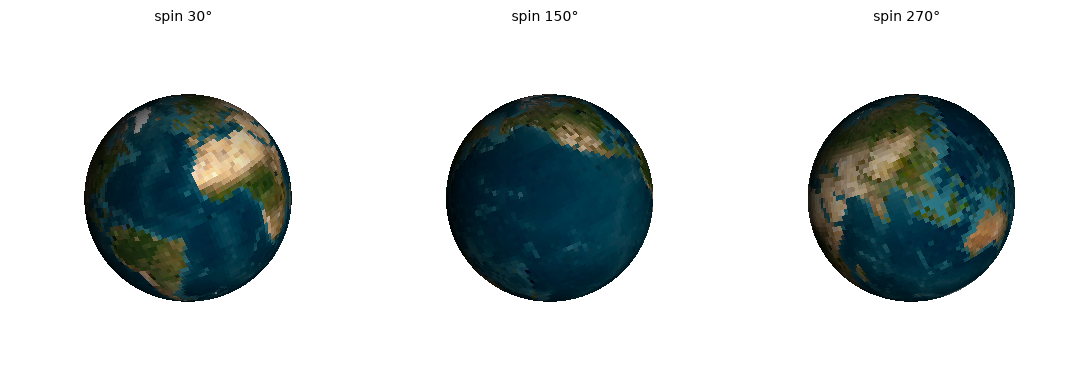

In [12]:
# Needs the network. zoom=3 is 64 tiles — enough for recognisable continents, light on the tile service.
earth = TexturedGlobe.from_provider(
    'Esri.WorldImagery', zoom=3, texture_n_lon=1440, texture_n_lat=720,
    n_lon=140, n_lat=70,
)
print('texture:', earth.glyph.texture.shape, '| mesh:', earth.glyph.n_lon, 'x', earth.glyph.n_lat)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.0), subplot_kw={'projection': '3d'})
for spin, sub in zip([30.0, 150.0, 270.0], axes):
    earth.draw(ax=sub, spin=spin, sun=(1.0, 0.30, 0.20), ambient=0.12)
    sub.set_title(f'spin {int(spin)}°', fontsize=10)
fig.tight_layout()

The same overlay machinery works on it — `project` and `points` do not care where the texture came from.

Text(0.5, 0.92, 'cities on the imagery globe')

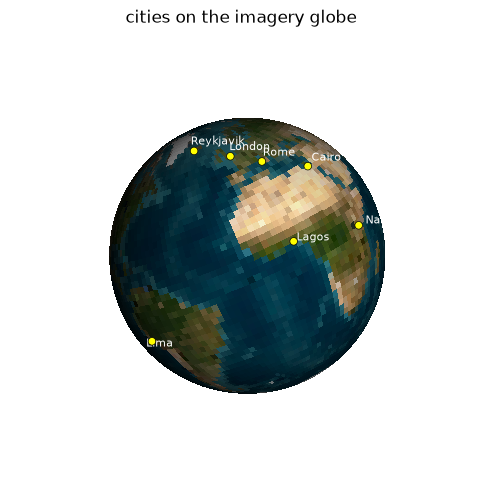

In [13]:
SPIN = 20.0
fig, ax = earth.draw(spin=SPIN, elev=10.0, azim=0.0, sun=(1.0, 0.3, 0.2), ambient=0.12)
earth.points(city_lon, lat=city_lat, spin=SPIN, color='yellow', s=30,
             edgecolors='black', linewidths=0.5, depthshade=False)
for (name, _), xyz, shown in zip(CITIES.items(),
                                 earth.project(city_lon, city_lat, spin=SPIN, altitude=0.07),
                                 earth.visible(earth.project(city_lon, city_lat, spin=SPIN))):
    if shown:
        ax.text(*xyz, name, fontsize=8, color='white')
ax.set_title('cities on the imagery globe')

## 10. Stepping a series of rasters — `animate`

`spin` turns the **camera** around one fixed texture. `animate` does the other thing: it holds the camera
still and steps **the data**, which is what a time series of a global field wants — sea-surface temperature,
sea ice, an anomaly field, anything whose signal crosses the antimeridian.

One colour scale is measured across the whole stack before any frame is drawn, so what moves on screen is a
change in the data. Normalising each frame to itself would make a constant field shimmer and let one outlier
frame rescale the rest; pass `vmin`/`vmax` to pin the scale instead.

**Overlays come along.** The coastline below is added once, before the animation, and re-placed on every
frame — so it stays registered to the ground while the field beneath it changes. That is why this is a method
and not something to assemble by hand: stepping the texture yourself means rebuilding the globe per frame, and
clearing the axes to do that throws the overlays away.

In [14]:
months = sorted(DATA.glob('global/ncep_tavg_*.tif'))
stack = [Dataset.read_file(str(p)) for p in months]
print(len(stack), 'monthly temperature grids')

12 monthly temperature grids


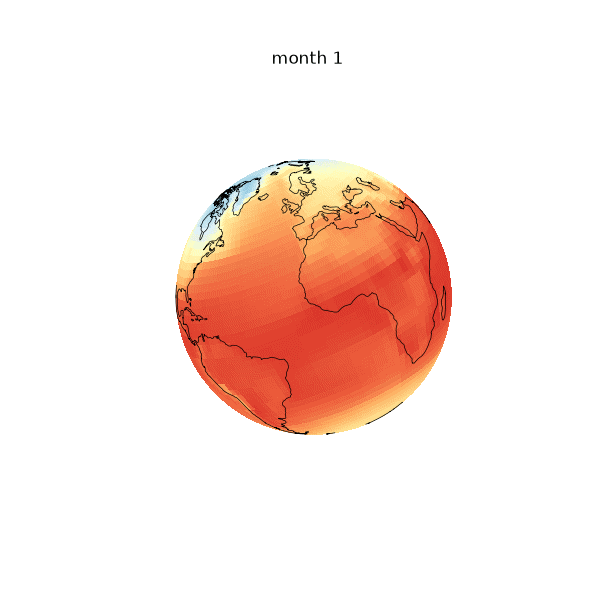

In [15]:
SPIN_AT = 20.0
seasons = TexturedGlobe.from_dataset(
    stack[0], shape=(180, 360), cmap='RdYlBu_r', n_lon=120, n_lat=60
)
seasons.draw(spin=SPIN_AT)          # a surface for the overlay to sit on
seasons.coastlines(linewidths=0.5)
anim = seasons.animate(
    stack, shape=(180, 360), cmap='RdYlBu_r', spin=SPIN_AT,
    titles=[f'month {i + 1}' for i in range(len(stack))], interval=250,
)
gif = embed_gif(anim, 4)
plt.close(seasons.fig)
gif

The warm band swings north and back over the twelve months while the coastline stays put — the two things a
data animation has to get right at once. Compare it with section 8's `spin`: there the data was fixed and the
vantage point moved, and conflating the two would leave a viewer unable to tell which.

## Where to go next

- **Notebook 12** — the 2-D orthographic globe, `Map.animate` and `Map.rotate`, with coastlines and colorbars.
- `TexturedGlobe.spin` turns the camera, `TexturedGlobe.animate` steps a stack — sections 8 and 10 above.
- **`docs/reference/textured_globe.md`** — the full `TexturedGlobe` API.
- **`docs/reference/animation.md`** — `save_animation`, shared by `Map` and `TexturedGlobe`.